# Triple-quantum build-up of a single 23Na spin under quadrupolar relaxation

*Contributed by Alexej Jerschow, 2026 (`user_py/na23_tqf_buildup.ipynb`).*

A spin-3/2 nucleus such as 23Na relaxes through the fluctuating quadrupolar
interaction. Outside extreme narrowing (`omega_0 tau_c` of order 1 or more)
the relaxation of single-quantum coherence is biexponential, and the
rank-1 single-quantum tensor `T(1,1)` that a 90-degree pulse creates feeds
the rank-3 tensor `T(3,1)`. A second pulse turns `T(3,1)` into triple-quantum
coherence `T(3,±3)`, which is what a triple-quantum-filtered (TQF) experiment
detects; its build-up with the preparation time is the curve calculated here
(Jaccard, Wimperis and Bodenhausen, *J. Chem. Phys.* 85, 6282 (1986)).

Settings: one 23Na spin, quadrupolar coupling constant `C_q = 2e5 Hz` with
an axially symmetric tensor, rotational correlation time `tau_c = 1 ns`,
Redfield relaxation towards thermal equilibrium at 298 K; the field is
14.1 T (a 600 MHz spectrometer). The experiment starts from the thermal
state turned transverse by a 90-degree pulse, and the build-up is followed
from 0 to 10 ms in 200 steps.

If you run this notebook on Binder and the Plotly figure does not show up,
run this in a cell before the plot:

```python
!pip install plotly

import plotly.io as pio

# Force the mimetype notebook renderer
pio.renderers.default = "plotly_mimetype+notebook"
```

In [1]:
import numpy as np
import spynach
from spynach.conventions import eeqq2nqi
from spynach.plotting import plot_time_series

C_q = 2e5            # quadrupolar coupling constant e^2 q Q / h, Hz
eta = 0.0            # asymmetry parameter
tau_c = 1e-9         # rotational correlation time, s
magnet = 14.1        # T
temperature = 298.0  # K
t_max = 10e-3        # s
nsteps = 200

## Spin system

The quadrupolar tensor comes from `eeqq2nqi` (the coupling constant, the
asymmetry, the spin and the Euler angles of its principal frame, as in
Spinach); in a liquid only its fluctuation matters, so the orientation is
immaterial. Redfield theory with secular retention gives the relaxation
superoperator, and `equilibrium: "dibari"` thermalises it so that the
thermal state at `temperature` is its stationary state (`"IME"`, the
inhomogeneous master equation, is the alternative; see the relaxation
guide).

In [2]:
nqi = eeqq2nqi(C_q, eta, 1.5, [0, 0, 0])
spin_system = spynach.create(
    {"isotopes": ["23Na"], "magnet": magnet},
    {
        "coupling": {"matrix": [[nqi.tolist()]]},
        "relaxation": ["redfield"],
        "rlx_keep": "secular",
        "equilibrium": "dibari",
        "temperature": temperature,
        "tau_c": [[tau_c]],
    },
)
spin_system = spynach.basis(spin_system, {"formalism": "sphten-liouv", "approximation": "none"})
spin_system = spynach.assume(spin_system, "nmr")
omega_0 = abs(spin_system.basefrqs[0])
print(f"{spin_system.basis.nstates} states; omega_0 / 2pi = {omega_0 / (2 * np.pi) / 1e6:.1f} MHz, "
      f"omega_0 tau_c = {omega_0 * tau_c:.2f}")

16 states; omega_0 / 2pi = 158.9 MHz, omega_0 tau_c = 1.00


## Relaxation superoperator

The basis holds the sixteen spherical tensors `T(l, m)` of a spin 3/2.
`state` accepts Spinach's `Tl,m` labels, and with the `"cheap"` method it
returns the unit vector of that basis state, which serves both to read the
relaxation matrix elements and, later, to project the trajectory. Among the
`m = +1` coherences, `T(1,1)` and `T(3,1)` are coupled by the quadrupolar
relaxation while `T(2,1)` relaxes on its own. The isotropic Hamiltonian of
a single spin with no shift is zero in the rotating frame, so only the
relaxation superoperator moves the state.

In [3]:
H = spynach.hamiltonian(spin_system)
R = spynach.relaxation(spin_system)
R_dense = np.asarray(R.toarray()) if hasattr(R, "toarray") else np.asarray(R)

tensor = lambda label: spynach.state(spin_system, [label], [0], "cheap")
T11, T21, T31, T33 = tensor("T1,1"), tensor("T2,1"), tensor("T3,1"), tensor("T3,3")
block = np.array([[(Tk @ R_dense @ Tj).real for Tj in (T11, T21, T31)] for Tk in (T11, T21, T31)])
print("R restricted to T(1,1), T(2,1), T(3,1), in Hz:")
print(np.round(block, 2))
rates = -np.linalg.eigvalsh(block[np.ix_([0, 2], [0, 2])])
print(f"fast and slow transverse rates: {rates.max():.2f} Hz and {rates.min():.2f} Hz")

R restricted to T(1,1), T(2,1), T(3,1), in Hz:
[[ -93.25    0.    -30.92]
 [   0.   -150.16    0.  ]
 [ -30.92    0.    -80.62]]
fast and slow transverse rates: 118.50 Hz and 55.37 Hz


## Build-up from the pulsed thermal state

`equilibrium` returns the thermal state (unit coefficient on the identity,
a Boltzmann-sized coefficient on `Lz`); a 90-degree pulse about `x`, applied
with `step` and the `Lx` commutation superoperator, turns it into
transverse magnetisation. The trajectory under `H + 1i R` is sampled at the
201 points from 0 to 10 ms and projected onto the tensor states: the
amplitude of `T(3,1)` is the TQF build-up, the amplitude of `T(1,1)` the
ordinary transverse decay, and `Lz` recovers towards its thermal value.
All curves are relative to the transverse magnetisation right after the
pulse.

In [4]:
rho_eq = spynach.equilibrium(spin_system)
Lx = spynach.operator(spin_system, "Lx", "23Na")
rho0 = spynach.step(spin_system, Lx, rho_eq, np.pi / 2)        # 90-degree pulse about x
L = H + 1j * R
dt = t_max / nsteps
traj = spynach.evolution(spin_system, L, rho0, dt, nsteps, "trajectory")
t = np.arange(nsteps + 1) * dt

m0 = abs(T11 @ rho0)                                            # transverse magnetisation after the pulse
a11 = np.abs(T11 @ traj) / m0                                   # T(1,1) decay
a31 = np.abs(T31 @ traj) / m0                                   # T(3,1) build-up
Lz = spynach.state(spin_system, "Lz", "23Na")
mz = (Lz @ traj).real / (Lz @ rho_eq).real                      # longitudinal recovery, relative to equilibrium
print(f"T(3,1) reaches {a31.max():.3f} at {t[a31.argmax()] * 1e3:.2f} ms; T(1,1) is down to {a11[-1]:.3f} "
      f"and Lz has recovered to {mz[-1]:.3f} of equilibrium at {t_max * 1e3:.0f} ms")

T(3,1) reaches 0.132 at 10.00 ms; T(1,1) is down to 0.413 and Lz has recovered to 0.326 of equilibrium at 10 ms


A second 90-degree pulse converts `T(3,1)` into the triple-quantum
coherences `T(3,±3)`; the TQF signal is proportional to their amplitude.
Applying the pulse to every point of the trajectory gives the build-up
curve as the experiment measures it (before the filter and the detection
period). The pulsed thermal state holds `T(1,+1)` and `T(1,-1)` in equal
measure, so both `T(3,±1)` components contribute to `T(3,3)` here; a start
from `L+` alone would give the `T(3,1)` curve scaled by a single
Wigner element instead.

In [5]:
after_pulse = spynach.step(spin_system, Lx, traj, np.pi / 2)
a33 = np.abs(T33 @ after_pulse) / m0
print(f"triple-quantum amplitude after the second pulse: {a33.max():.3f} at {t[a33.argmax()] * 1e3:.2f} ms")

triple-quantum amplitude after the second pulse: 0.087 at 10.00 ms


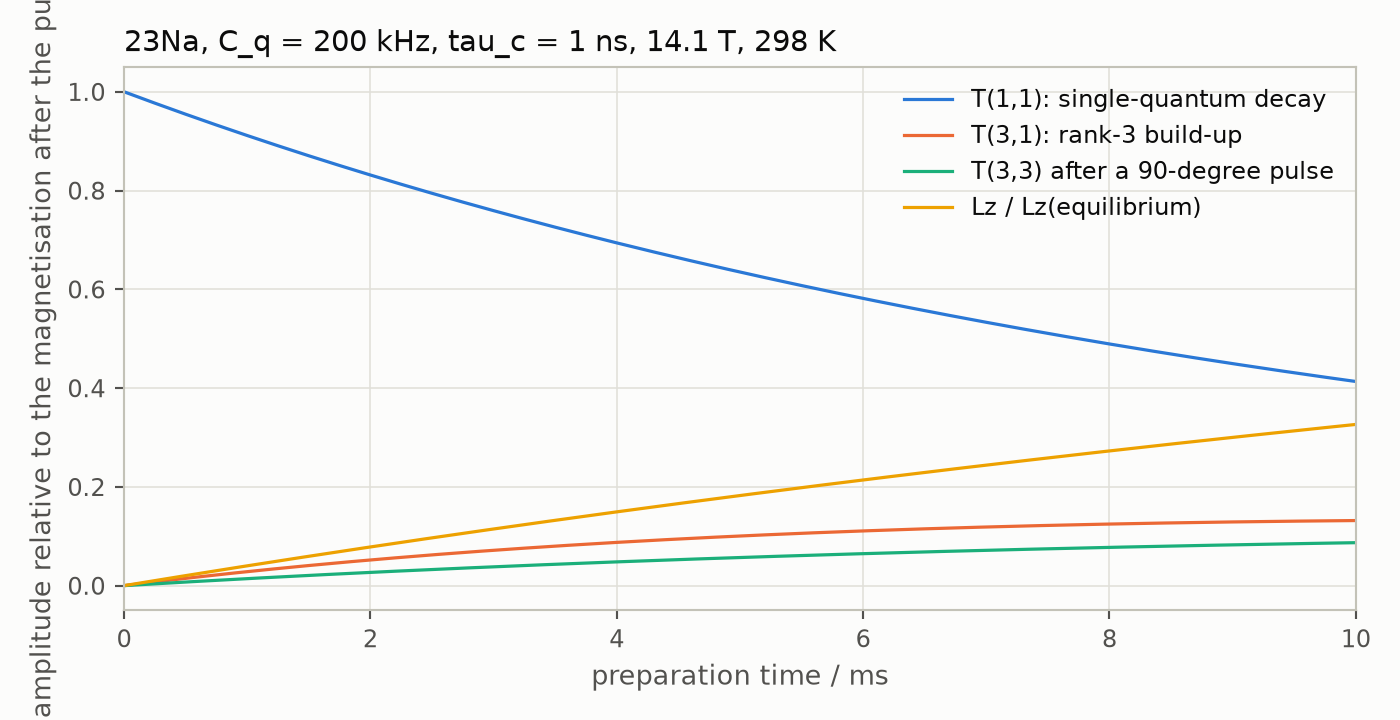

In [6]:
plot_time_series(
    t * 1e3,
    [a11, a31, a33, mz],
    names=[
        "T(1,1): single-quantum decay",
        "T(3,1): rank-3 build-up",
        "T(3,3) after a 90-degree pulse",
        "Lz / Lz(equilibrium)",
    ],
    xlabel="preparation time / ms",
    ylabel="amplitude relative to the magnetisation after the pulse",
    title="23Na, C_q = 200 kHz, tau_c = 1 ns, 14.1 T, 298 K",
)

## Check against the biexponential form

Restricted to `T(1,1)` and `T(3,1)`, the relaxation matrix is a symmetric
2 x 2 block, so its exponential is `alpha 1 + beta R` and the transfer
element is `beta` times the cross-relaxation rate: the build-up is the
difference of two exponentials with the fast and slow rates above, the
form Jaccard, Wimperis and Bodenhausen give for the TQF signal. The
thermalisation does not touch the transverse block, so the curve is the
same as from a bare `L+` start.

In [7]:
r_fast, r_slow = rates.max(), rates.min()
cross = block[0, 2]
analytic = abs(cross) * (np.exp(-r_slow * t) - np.exp(-r_fast * t)) / (r_fast - r_slow)
print(f"largest difference from the biexponential build-up: {np.abs(a31 - analytic).max():.2e}")

largest difference from the biexponential build-up: 5.29e-08
